# ShapeFit extensions with the final wiggle-depth estimator: compression chains -> best fit -> cosmological reinterpretation

Same pipeline and layout as `shapefit_extensions_cosmology_examples.ipynb`, but with the
wiggle-depth (`dgam`) extraction **distilled to the method that ships in desilike**:
`ShapeFitTheory(gam_estimator='rms_phase_detrend')` — the RMS of $\ln W=\ln(P/P_{\rm now})$
over a window fixed in phase $x=k\,r_d$, after removing a cubic in $\ln k$
(`desilike/theories/galaxy_clustering/wiggle.py`). Configurations:

| config | freed shape parameters | note |
|---|---|---|
| `baseline` | `dm` | BGV21 with the DESI MG choice `dn = 0` |
| `dgam` | `dm`, `dgam` | wiggle depth, final estimator |
| `dc` | `dm`, `dc` | curvature, converged pivot grid |

`dA` stays fixed at 1 in every compression (degenerate with `b1` for a single tracer);
$\log A$ is nevertheless constrained in the reinterpretation because `df` measures
$f\sqrt{A_p}$. Chains and compressed summaries are cached under `_wiggle_tests/`, so the
notebook can be run in passes (set `WIGGLE_NB_REINTERP=0` to stop after the compression);
the compression widths to watch are $\sigma(\delta\gamma)\approx0.11$,
$\sigma(\delta m)\approx0.015$, $\sigma(\delta c)\approx0.05$ (Fisher/Monte-Carlo,
report §9.1) — **not** the under-dispersed values of the older notebook (§10).

## 1. Fake power-spectrum data (fiducial cosmology by default)

In [43]:
import os
import gc
import numpy as np
from matplotlib import pyplot as plt
from cosmoprimo.fiducial import DESI
import lsstypes

FIDUCIAL = ('DESI', {'engine': 'class'})
# data at the fiducial cosmology by default; set e.g.
# SHIFT = dict(omega_cdm=0.1206 * 1.02, n_s=0.9649 + 0.015, h=0.6736 * 0.995) for a shifted truth
SHIFT = {}
cosmo_truth = DESI(engine='class').clone(base='input', **SHIFT) if SHIFT else DESI(engine='class')
truth = {name: float(cosmo_truth[name]) for name in ['omega_cdm', 'n_s', 'h', 'omega_b',]}
truth['m_ncdm'] = float(np.sum(cosmo_truth['m_ncdm']))

edges = np.linspace(0., 0.3, 31)
edges = np.column_stack([edges[:-1], edges[1:]])
k = np.mean(edges, axis=-1)
nmodes = 4. * np.pi / 3. * (edges[..., 1]**3 - edges[..., 0]**3)
z = 1.
pk = cosmo_truth.get_fourier().pk_interpolator(of='delta_cb')(k, z=z)
b = 2.
f = cosmo_truth.growth_rate(z)
shotnoise = np.ones_like(k) / 5e-4
volume = 1e10

ells = (0, 2, 4)
poles = np.array([(b**2 + 2. / 3. * f * b + 1. / 5. * f**2) * pk + shotnoise,
                  (4. / 3. * f * b + 4. / 7. * f**2) * pk,
                  8. / 35 * f**2 * pk], dtype='f8')

from lsstypes import Mesh2SpectrumPole, Mesh2SpectrumPoles
mean = Mesh2SpectrumPoles([Mesh2SpectrumPole(k=k, k_edges=edges, num_raw=value,
                                             num_shotnoise=(ell == 0) * shotnoise, ell=ell)
                           for ell, value in zip(ells, poles)])
cov = np.diag(np.concatenate([2. * (2. * np.pi)**3 / (2 * ell + 1) / (volume * nmodes) * poles[0]**2
                              for ell in ells]))
rng = np.random.RandomState(seed=42)
mocks = [mean.clone(value=rng.multivariate_normal(mean.value().ravel(), cov)) for i in range(1001)]
data, mocks = mocks[0], mocks[1:]
del mean, poles, cov
print('truth: omega_cdm=%.4f n_s=%.4f h=%.4f  ->  omega_m=%.4f'
      % (truth['omega_cdm'], truth['n_s'], truth['h'],
         (truth['omega_cdm'] + cosmo_truth['omega_b']) / truth['h']**2))

truth: omega_cdm=0.1200 n_s=0.9649 h=0.6736  ->  omega_m=0.3138


## 2. Compression chains, one configuration per run

`dn` stays fixed to 0 everywhere (the DESI MG configuration) and `dA` to 1. Note the wide
`ref` boxes: the older notebook initialised its walkers inside $\pm0.002$ of the fiducial and
never escaped, which is why its quoted errors were 3-4x too small.

In [19]:
from desilike.theories.galaxy_clustering import ShapeFitSpectrum2Template, ShapeFitTheory
from desilike.theories.galaxy_clustering.full_shape import (KaiserTracerSpectrum2Poles,
                                                            KaiserPTSpectrum2Poles)
from desilike.observables.galaxy_clustering import Spectrum2PolesObservable
from desilike.likelihoods import ObservablesGaussianLikelihood
from desilike import setup_logging, build, get_params, Sampler, Posterior
from desilike.samplers import Emcee
from desilike.theories.primordial_cosmology import CosmoprimoCosmology
from desilike.samples import MCSamples

setup_logging()
CONFIGS = ['baseline', 'dgam']
EXTRA = {'baseline': None, 'dgam': 'dgam', 'dc': 'dc'}
CHAIN_DIR = '_wiggle_tests'
os.makedirs(CHAIN_DIR, exist_ok=True)

def build_compression(config):
    template = ShapeFitSpectrum2Template(z=z, fiducial=FIDUCIAL)   # final dgam estimator inside
    pt = KaiserPTSpectrum2Poles(k=k, template=template, ells=ells)
    theory = KaiserTracerSpectrum2Poles(k=k, pt=pt, template=template, ells=ells, nbar=1e-4)
    data_sel = data.get(ells=[0, 2]).select(k=(0.02, 0.2))
    covariance = lsstypes.cov(mocks).at.observable.match(data_sel)
    observable = Spectrum2PolesObservable(data=data_sel, covariance=covariance, theory=theory)
    params = get_params(observable)
    params['b1'].update(value=b)
    params['dA'].update(fixed=True, value=1.)
    params['dm'].update(ref={'limits': [-0.05, 0.05]})
    params['df'].update(ref={'limits': [0.9, 1.1]})
    for name in ['qpar', 'qper']:
        params[name].update(ref={'limits': [0.95, 1.05]})
    if EXTRA[config] is not None:
        params[EXTRA[config]].update(fixed=False, ref={'limits': [-0.3, 0.3]})
    likelihood = ObservablesGaussianLikelihood(observables=[observable])
    return observable, likelihood

def load_comp(config):
    fn = os.path.join(CHAIN_DIR, 'comp_%s.npz' % config)
    if not os.path.exists(fn):
        return None
    with np.load(fn, allow_pickle=True) as npz:
        return dict(names=list(npz['names']), mean=npz['mean'], covariance=npz['covariance'])

def load_chain(config):
    fn = os.path.join(CHAIN_DIR, 'chain_%s' % config, 'samples_1.h5')
    return MCSamples.read(fn) if os.path.exists(fn) else None

comps, chains = {}, {}
for config in CONFIGS:
    comp, chain = load_comp(config), load_chain(config)
    #os.remove(os.path.join(CHAIN_DIR, 'chain_' + config, "samples_1.h5"))

    if comp is None or chain is None or 1:
        observable, likelihood = build_compression(config)
        sampler = Sampler(build(Posterior(likelihood)), kernel=Emcee(), rng=42,
                          output_dir=os.path.join(CHAIN_DIR, 'chain_' + config))
        chain = sampler.run(min_steps=250, gelman_rubin=1.05).remove_burnin(0.3)
        del sampler, likelihood, observable
        gc.collect()
        names = [n for n in ['qpar', 'qper', 'df', 'dm'] + ([EXTRA[config]] if EXTRA[config] else [])
                 if n in chain.names()]
        comp = dict(names=names, mean=np.array([chain.mean(n) for n in names]),
                    covariance=np.cov(np.column_stack([chain[n].value.ravel() for n in names]), rowvar=False))
        np.savez(os.path.join(CHAIN_DIR, 'comp_%s.np' % config + 'z'), names=np.array(names),
                 mean=comp['mean'], covariance=comp['covariance'])
    comps[config], chains[config] = comp, chain
for config in CONFIGS:
    c = comps[config]
    print('== %-8s ==' % config)
    for n, m, cc in zip(c['names'], c['mean'], np.diag(c['covariance'])):
        print('   %-5s %+.4f +/- %.4f' % (n, m, np.sqrt(cc)))

[000002.00]  10-16 00:40  EnsembleSampler              INFO     Varied parameters: ['qpar', 'qper', 'df', 'dm', 'b1', 'sn0']
[000002.00]  10-16 00:40  EnsembleSampler              INFO     Samples will be written to: _wiggle_tests/chain_baseline


/global/common/software/desi/users/adematti/perlmutter/cosmodesiconda/20260321-1.0.0/code/cosmoprimo/main/lib/python3.12/site-packages/cosmoprimo/eisenstein_hu.py:25: UserWarning: EisensteinHuNoWiggleEngine cannot cope with massive neutrinos
  warnings.warn(


[000003.21]  10-16 00:40  Emcee                        INFO     total likelihood evaluations: 7176
[000003.22]  10-16 00:40  EnsembleSampler              INFO     Diagnostics:
[000003.25]  10-16 00:40  EnsembleSampler              INFO     Gelman-Rubin: 2.52
[000003.25]  10-16 00:40  EnsembleSampler              INFO     2.52 >= 1.05 (not passed)
[000003.25]  10-16 00:40  EnsembleSampler              INFO     Geweke: 2.72
[000003.25]  10-16 00:40  EnsembleSampler              INFO     Effective Sample Size: 227
[000003.59]  10-16 00:40  Emcee                        INFO     total likelihood evaluations: 14376
[000003.60]  10-16 00:40  EnsembleSampler              INFO     Diagnostics:
[000003.62]  10-16 00:40  EnsembleSampler              INFO     Gelman-Rubin: 1.13
[000003.63]  10-16 00:40  EnsembleSampler              INFO     1.13 >= 1.05 (not passed)
[000003.63]  10-16 00:40  EnsembleSampler              INFO     Geweke: 0.624
[000003.63]  10-16 00:40  EnsembleSampler              

/global/common/software/desi/users/adematti/perlmutter/cosmodesiconda/20260321-1.0.0/code/cosmoprimo/main/lib/python3.12/site-packages/cosmoprimo/eisenstein_hu.py:25: UserWarning: EisensteinHuNoWiggleEngine cannot cope with massive neutrinos
  warnings.warn(


[000007.78]  10-16 00:40  Emcee                        INFO     total likelihood evaluations: 8372
[000007.79]  10-16 00:40  EnsembleSampler              INFO     Diagnostics:
[000007.82]  10-16 00:40  EnsembleSampler              INFO     Gelman-Rubin: 2.27
[000007.82]  10-16 00:40  EnsembleSampler              INFO     2.27 >= 1.05 (not passed)
[000007.82]  10-16 00:40  EnsembleSampler              INFO     Geweke: 2.07
[000007.82]  10-16 00:40  EnsembleSampler              INFO     Effective Sample Size: 240
[000008.18]  10-16 00:40  Emcee                        INFO     total likelihood evaluations: 16772
[000008.18]  10-16 00:40  EnsembleSampler              INFO     Diagnostics:
[000008.22]  10-16 00:40  EnsembleSampler              INFO     Gelman-Rubin: 1.09
[000008.22]  10-16 00:40  EnsembleSampler              INFO     1.09 >= 1.05 (not passed)
[000008.22]  10-16 00:40  EnsembleSampler              INFO     Geweke: 0.644
[000008.22]  10-16 00:40  EnsembleSampler              

## 3. Sanity check against the theory side

Chain mean vs what `ShapeFitTheory` (final estimator) predicts at the truth, and chain width
vs the Fisher forecast.

In [14]:
theory = ShapeFitTheory(z=z, fiducial=FIDUCIAL, cosmo=CosmoprimoCosmology(engine='camb', fiducial=FIDUCIAL))
pipe_theory = build(theory)
defaults = {param.name: param._value for param in get_params(theory)}
pipe_theory({**defaults, **truth})
truth_compressed = {name: float(getattr(theory, name))
                    for name in ['qpar', 'qper', 'df', 'dm', 'dc', 'deps', 'dgam', 'dn']}
# Fisher/MC widths for the ANALYTIC Gaussian covariance the mocks are drawn from.
# NB: the lsstypes-matched covariance used by the likelihood below is 3-10x smaller in
# variance (report sec. 10), so chain widths come out ~3.6x tighter than these numbers.
FISHER = {'qpar': 0.0115, 'qper': 0.0199, 'df': 0.0321, 'dm': 0.0148, 'dgam': 0.1128, 'dc': 0.0486}
for config in (CONFIGS if RUN_PLOTS else []):
    c = comps[config]
    line = '== %-8s' % config
    for n, m, cc in zip(c['names'], c['mean'], np.diag(c['covariance'])):
        line += '  %s: theory %+.4f  chain %+.4f +/- %.4f (fisher %.4f)' % (
            n, truth_compressed[n], m, np.sqrt(cc), FISHER.get(n, np.nan))
    print(line)
del theory, pipe_theory, defaults
gc.collect()

/global/common/software/desi/users/adematti/perlmutter/cosmodesiconda/20260321-1.0.0/code/cosmoprimo/main/lib/python3.12/site-packages/cosmoprimo/eisenstein_hu.py:25: UserWarning: EisensteinHuNoWiggleEngine cannot cope with massive neutrinos
  warnings.warn(


== baseline  qpar: theory +1.0000  chain +1.0001 +/- 0.0026 (fisher 0.0115)  qper: theory +1.0000  chain +0.9941 +/- 0.0049 (fisher 0.0199)  df: theory +1.0001  chain +0.9906 +/- 0.0102 (fisher 0.0321)  dm: theory +0.0007  chain -0.0009 +/- 0.0061 (fisher 0.0148)
== dgam_detrend  qpar: theory +1.0000  chain +1.0001 +/- 0.0027 (fisher 0.0115)  qper: theory +1.0000  chain +0.9938 +/- 0.0052 (fisher 0.0199)  df: theory +1.0001  chain +0.9898 +/- 0.0105 (fisher 0.0321)  dm: theory +0.0007  chain -0.0007 +/- 0.0062 (fisher 0.0148)  dgam: theory +0.0022  chain -0.0183 +/- 0.0321 (fisher 0.1128)
== dgam      qpar: theory +1.0000  chain +1.0001 +/- 0.0027 (fisher 0.0115)  qper: theory +1.0000  chain +0.9939 +/- 0.0052 (fisher 0.0199)  df: theory +1.0001  chain +0.9901 +/- 0.0104 (fisher 0.0321)  dm: theory +0.0007  chain -0.0009 +/- 0.0061 (fisher 0.0148)  dgam: theory +0.0022  chain -0.0183 +/- 0.0318 (fisher 0.1128)
== dc        qpar: theory +1.0000  chain +1.0003 +/- 0.0027 (fisher 0.0115) 

1014

## 4. Compression chains

Removed no burn in
Removed no burn in
Removed no burn in
Removed no burn in
[000108.03]  10-16 00:39  matplotlib.mathtext          INFO     Substituting symbol \perp from STIXGeneral
[000108.04]  10-16 00:39  matplotlib.mathtext          INFO     Substituting symbol \perp from STIXGeneral
[000109.46]  10-16 00:39  matplotlib.mathtext          INFO     Substituting symbol \perp from STIXGeneral
[000109.46]  10-16 00:39  matplotlib.mathtext          INFO     Substituting symbol \perp from STIXGeneral


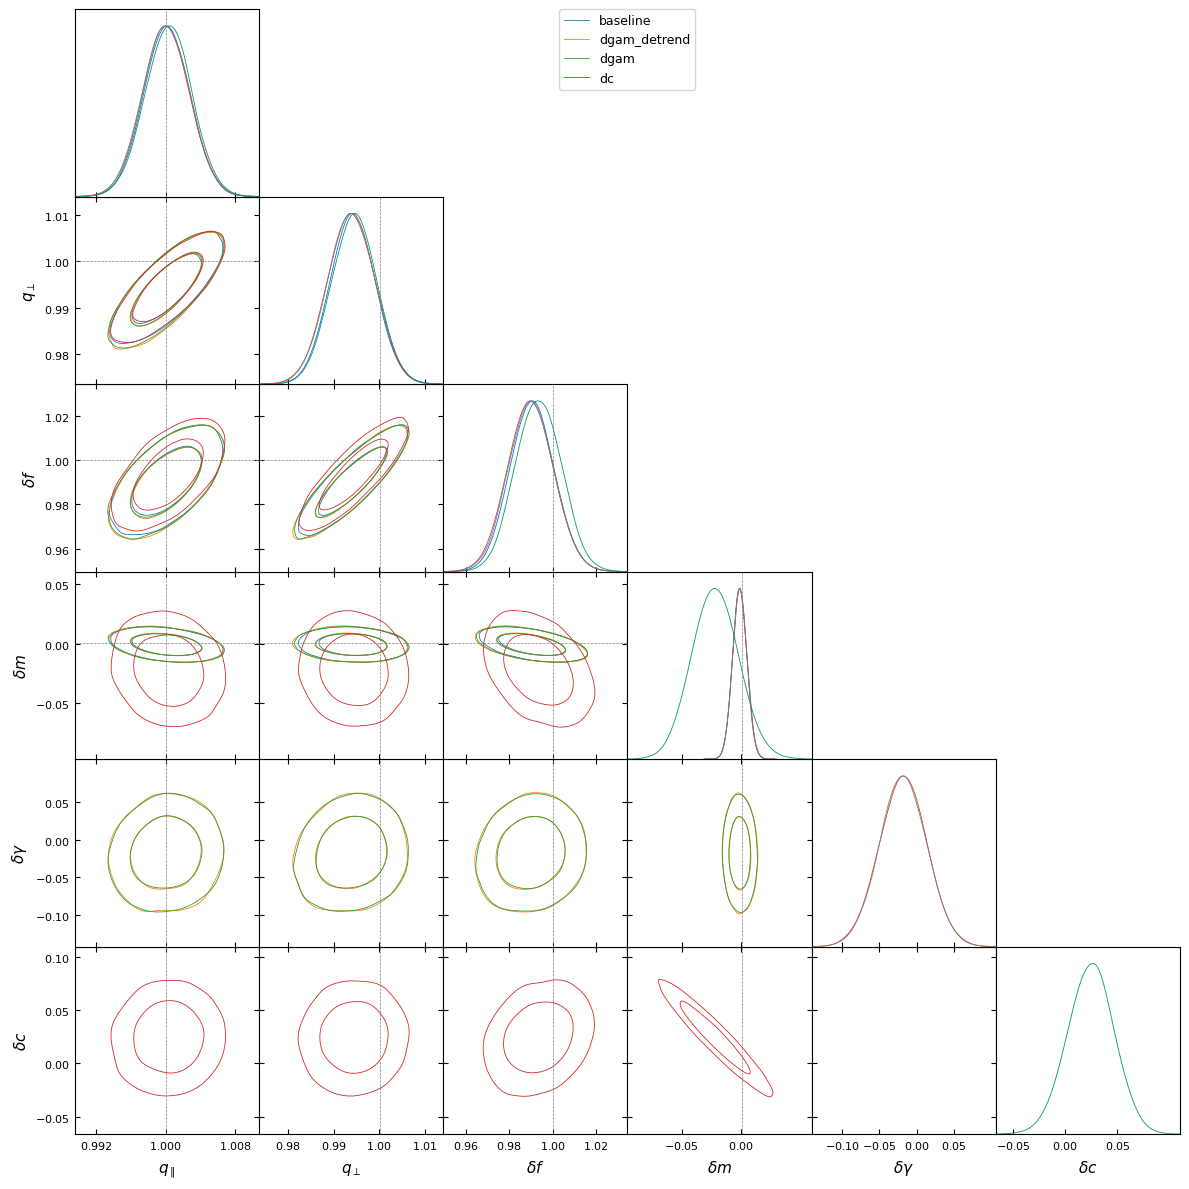

In [15]:
if RUN_PLOTS:
    from desilike.samples import plotting
    overlay = [chains[c][::5] for c in CONFIGS]
    plotting.plot_triangle(overlay, params=['qpar', 'qper', 'df', 'dm', 'dgam', 'dc'],
                           labels=CONFIGS, filled=False,
                           markers={n: truth_compressed[n] for n in ['qpar', 'qper', 'df', 'dm']},
                           colors=['C%d' % i for i in range(len(CONFIGS))])
    plt.show(); plt.close('all')
    gc.collect()

## 5. Cosmological reinterpretation, one chain per (configuration, dgam definition)

Each compressed measurement (chain mean + covariance) becomes the data of a
`ShapeFitCompressionObservable`; the posterior over $(h, \omega_{\rm cdm}, \log A, \omega_b, n_s)$
is sampled with the theory emulated on the same box as the original notebook, $\omega_b$ freed
against its BBN prior. For the `dgam` configuration the **same compression** is reinterpreted
with each shipped theory-side definition (`gam_estimator='rms_legacy' | 'rms_phase' |
'rms_phase_detrend'`, forwarded by the observable to `ShapeFitTheory`), so the spread between
those chains *is* the effect of the estimator definition on the cosmology. On memory-tight
machines run one (config, estimator) per kernel via `WIGGLE_NB_CONFIGS` / `WIGGLE_NB_ESTS`;
everything caches under `_wiggle_tests/`.

In [31]:
ESTS = os.environ.get('WIGGLE_NB_ESTS', 'rms_legacy,rms_phase,rms_phase_detrend').split(',')
from desilike.observables.galaxy_clustering import ShapeFitCompressionObservable
from desilike.emulators import Emulator, Space

COSMO_PARAMS = ['h', 'omega_cdm', 'logA', 'omega_b', 'n_s']
samples = {}
KEYS = []
for config in CONFIGS:
    KEYS += [config] if config != 'dgam' else ['dgam_%s' % e for e in ESTS]
if RUN_REINTERP:
    for config in CONFIGS:
        # the SAME compression measurement, reinterpreted with each theory-side dgam
        # definition: the spread between these chains is the effect of the estimator on cosmology
        for est in (ESTS if config == 'dgam' else [None]):
            key = config if est is None else '%s_%s' % (config, est)
            fn = os.path.join(CHAIN_DIR, 'reinterp_%s' % key, 'samples_1.h5')
            if os.path.exists(fn):
                #samples[key] = MCSamples.read(fn).remove_burnin(0.4)
                os.remove(fn)
                #continue
            c = comps[config]
            kw = {} if est is None else dict(gam_estimator=est)
            observable = ShapeFitCompressionObservable(data=list(c['mean']), covariance=c['covariance'],
                                                       parameters=c['names'], z=z, fiducial=FIDUCIAL,
                                                       cosmo=CosmoprimoCosmology(engine='camb', fiducial=FIDUCIAL),
                                                       **kw)
            params = get_params(observable)
            params['omega_b'].update(fixed=False,
                                     prior=dict(dist='norm', loc=DESI(engine='camb')['omega_b'], scale=2 * 0.00055),
                                     ref=dict(dist='norm', loc=DESI(engine='camb')['omega_b'], scale=0.0003),
                                     fd=dict(eps=0.0015), latex=r'\omega_b')
            params['n_s'].update(fixed=False, value=DESI(engine='camb')['n_s'],
                                 prior=dict(dist='norm', loc=0.9649, scale=0.0084),
                                 ref=dict(dist='norm', loc=DESI(engine='camb')['n_s'], scale=0.1),
                                 fd=dict(eps=0.005), latex='n_s')
            emulator = Emulator(observable.theory, Space(bounds={'h': (0.65, 0.70),
                                                                 'omega_cdm': (0.116, 0.128),
                                                                 'logA': (2.97, 3.11),
                                                                 'omega_b': (0.020005, 0.024995),
                                                                 'n_s': (0.8, 1.1)}), budget=1)
            emulator.train()
            observable.update(theory=emulator.to_calculator())
            likelihood = ObservablesGaussianLikelihood(observables=[observable])
            sampler = Sampler(build(Posterior(likelihood)), kernel=Emcee(), rng=42,
                              output_dir=os.path.join(CHAIN_DIR, 'reinterp_' + key))
            samples[key] = sampler.run(min_steps=500, gelman_rubin=1.01).remove_burnin(0.4)
            del sampler, likelihood, observable, emulator
            gc.collect()
            import jax; jax.clear_caches()
else:
    for key in KEYS:
        fn = os.path.join(CHAIN_DIR, 'reinterp_%s' % key, 'samples_1.h5')
        if os.path.exists(fn):
            samples[key] = MCSamples.read(fn).remove_burnin(0.4)
    print('reinterpretation loaded from cache:', sorted(samples))

/global/common/software/desi/users/adematti/perlmutter/cosmodesiconda/20260321-1.0.0/code/cosmoprimo/main/lib/python3.12/site-packages/cosmoprimo/eisenstein_hu.py:25: UserWarning: EisensteinHuNoWiggleEngine cannot cope with massive neutrinos
  warnings.warn(


[001008.89]  10-16 00:57  Emulator                     INFO     training on 11 nodes over 5 parameters; 0 handled exactly
[001008.90]  10-16 00:57  Emulator                     INFO     node box: h [0.65, 0.7], omega_cdm [0.116, 0.128], logA [2.97, 3.11], omega_b [0.020005, 0.024995], n_s [0.8, 1.1]
[001008.90]  10-16 00:57  TrainingSet                  INFO     11/11 nodes to evaluate; no checkpoint (nothing is resumable)
[001033.24]  10-16 00:57  TrainingSet                  INFO     training complete (11/11 nodes)
[001034.37]  10-16 00:57  EnsembleSampler              INFO     Varied parameters: ['h', 'omega_cdm', 'logA', 'omega_b', 'n_s']
[001034.37]  10-16 00:57  EnsembleSampler              INFO     Samples will be written to: _wiggle_tests/reinterp_baseline
[001036.83]  10-16 00:57  Emcee                        INFO     total likelihood evaluations: 5980
[001036.90]  10-16 00:57  EnsembleSampler              INFO     Diagnostics:
[001036.92]  10-16 00:57  EnsembleSampler        

/global/common/software/desi/users/adematti/perlmutter/cosmodesiconda/20260321-1.0.0/code/cosmoprimo/main/lib/python3.12/site-packages/cosmoprimo/eisenstein_hu.py:25: UserWarning: EisensteinHuNoWiggleEngine cannot cope with massive neutrinos
  warnings.warn(


[001047.86]  10-16 00:58  Emulator                     INFO     training on 11 nodes over 5 parameters; 0 handled exactly
[001047.87]  10-16 00:58  Emulator                     INFO     node box: h [0.65, 0.7], omega_cdm [0.116, 0.128], logA [2.97, 3.11], omega_b [0.020005, 0.024995], n_s [0.8, 1.1]
[001047.87]  10-16 00:58  TrainingSet                  INFO     11/11 nodes to evaluate; no checkpoint (nothing is resumable)
[001072.05]  10-16 00:58  TrainingSet                  INFO     training complete (11/11 nodes)
[001073.20]  10-16 00:58  EnsembleSampler              INFO     Varied parameters: ['h', 'omega_cdm', 'logA', 'omega_b', 'n_s']
[001073.20]  10-16 00:58  EnsembleSampler              INFO     Samples will be written to: _wiggle_tests/reinterp_dgam_rms_legacy
[001075.70]  10-16 00:58  Emcee                        INFO     total likelihood evaluations: 5980
[001075.77]  10-16 00:58  EnsembleSampler              INFO     Diagnostics:
[001075.79]  10-16 00:58  EnsembleSampler 

/global/common/software/desi/users/adematti/perlmutter/cosmodesiconda/20260321-1.0.0/code/cosmoprimo/main/lib/python3.12/site-packages/cosmoprimo/eisenstein_hu.py:25: UserWarning: EisensteinHuNoWiggleEngine cannot cope with massive neutrinos
  warnings.warn(


[001091.16]  10-16 00:58  Emulator                     INFO     training on 11 nodes over 5 parameters; 0 handled exactly
[001091.16]  10-16 00:58  Emulator                     INFO     node box: h [0.65, 0.7], omega_cdm [0.116, 0.128], logA [2.97, 3.11], omega_b [0.020005, 0.024995], n_s [0.8, 1.1]
[001091.16]  10-16 00:58  TrainingSet                  INFO     11/11 nodes to evaluate; no checkpoint (nothing is resumable)
[001115.57]  10-16 00:59  TrainingSet                  INFO     training complete (11/11 nodes)
[001116.74]  10-16 00:59  EnsembleSampler              INFO     Varied parameters: ['h', 'omega_cdm', 'logA', 'omega_b', 'n_s']
[001116.75]  10-16 00:59  EnsembleSampler              INFO     Samples will be written to: _wiggle_tests/reinterp_dgam_rms_phase
[001119.24]  10-16 00:59  Emcee                        INFO     total likelihood evaluations: 5980
[001119.30]  10-16 00:59  EnsembleSampler              INFO     Diagnostics:
[001119.32]  10-16 00:59  EnsembleSampler  

/global/common/software/desi/users/adematti/perlmutter/cosmodesiconda/20260321-1.0.0/code/cosmoprimo/main/lib/python3.12/site-packages/cosmoprimo/eisenstein_hu.py:25: UserWarning: EisensteinHuNoWiggleEngine cannot cope with massive neutrinos
  warnings.warn(


[001134.79]  10-16 00:59  Emulator                     INFO     training on 11 nodes over 5 parameters; 0 handled exactly
[001134.79]  10-16 00:59  Emulator                     INFO     node box: h [0.65, 0.7], omega_cdm [0.116, 0.128], logA [2.97, 3.11], omega_b [0.020005, 0.024995], n_s [0.8, 1.1]
[001134.79]  10-16 00:59  TrainingSet                  INFO     11/11 nodes to evaluate; no checkpoint (nothing is resumable)
[001159.54]  10-16 00:59  TrainingSet                  INFO     training complete (11/11 nodes)
[001160.71]  10-16 00:59  EnsembleSampler              INFO     Varied parameters: ['h', 'omega_cdm', 'logA', 'omega_b', 'n_s']
[001160.71]  10-16 00:59  EnsembleSampler              INFO     Samples will be written to: _wiggle_tests/reinterp_dgam_rms_phase_detrend
[001163.33]  10-16 00:59  Emcee                        INFO     total likelihood evaluations: 5980
[001163.41]  10-16 00:59  EnsembleSampler              INFO     Diagnostics:
[001163.43]  10-16 00:59  EnsembleS

In [32]:
omega_b_fid = DESI(engine='camb')['omega_b']
omega_m_truth = (truth['omega_cdm'] + omega_b_fid) / truth['h']**2
for key in samples:
    samp = samples[key]
    arr = {name: np.asarray(samp[name].value).ravel() for name in COSMO_PARAMS}
    omega_m = (arr['omega_cdm'] + arr['omega_b']) / arr['h']**2
    print('%-26s omega_m = %.4f +/- %.4f (%.1f%%)  pull = %+.1f sigma | h = %.4f +/- %.4f  logA = %.3f +/- %.3f  omega_b = %.5f +/- %.5f (BBN prior 0.00055)'
          % (key, omega_m.mean(), omega_m.std(), 100*omega_m.std()/omega_m.mean(),
             (omega_m.mean() - omega_m_truth)/omega_m.std(), arr['h'].mean(), arr['h'].std(),
             arr['logA'].mean(), arr['logA'].std(), arr['omega_b'].mean(), arr['omega_b'].std()))

baseline                   omega_m = 0.3082 +/- 0.0052 (1.7%)  pull = -1.1 sigma | h = 0.6795 +/- 0.0083  logA = 3.044 +/- 0.016  omega_b = 0.02268 +/- 0.00086 (BBN prior 0.00055)
dgam_rms_legacy            omega_m = 0.3096 +/- 0.0053 (1.7%)  pull = -0.8 sigma | h = 0.6765 +/- 0.0080  logA = 3.042 +/- 0.017  omega_b = 0.02231 +/- 0.00077 (BBN prior 0.00055)
dgam_rms_phase             omega_m = 0.3098 +/- 0.0051 (1.6%)  pull = -0.8 sigma | h = 0.6759 +/- 0.0079  logA = 3.042 +/- 0.017  omega_b = 0.02224 +/- 0.00077 (BBN prior 0.00055)
dgam_rms_phase_detrend     omega_m = 0.3100 +/- 0.0051 (1.7%)  pull = -0.7 sigma | h = 0.6756 +/- 0.0075  logA = 3.043 +/- 0.016  omega_b = 0.02223 +/- 0.00073 (BBN prior 0.00055)


## 6. Reinterpretation chains

Removed no burn in
Removed no burn in
Removed no burn in
Removed no burn in
Removed no burn in


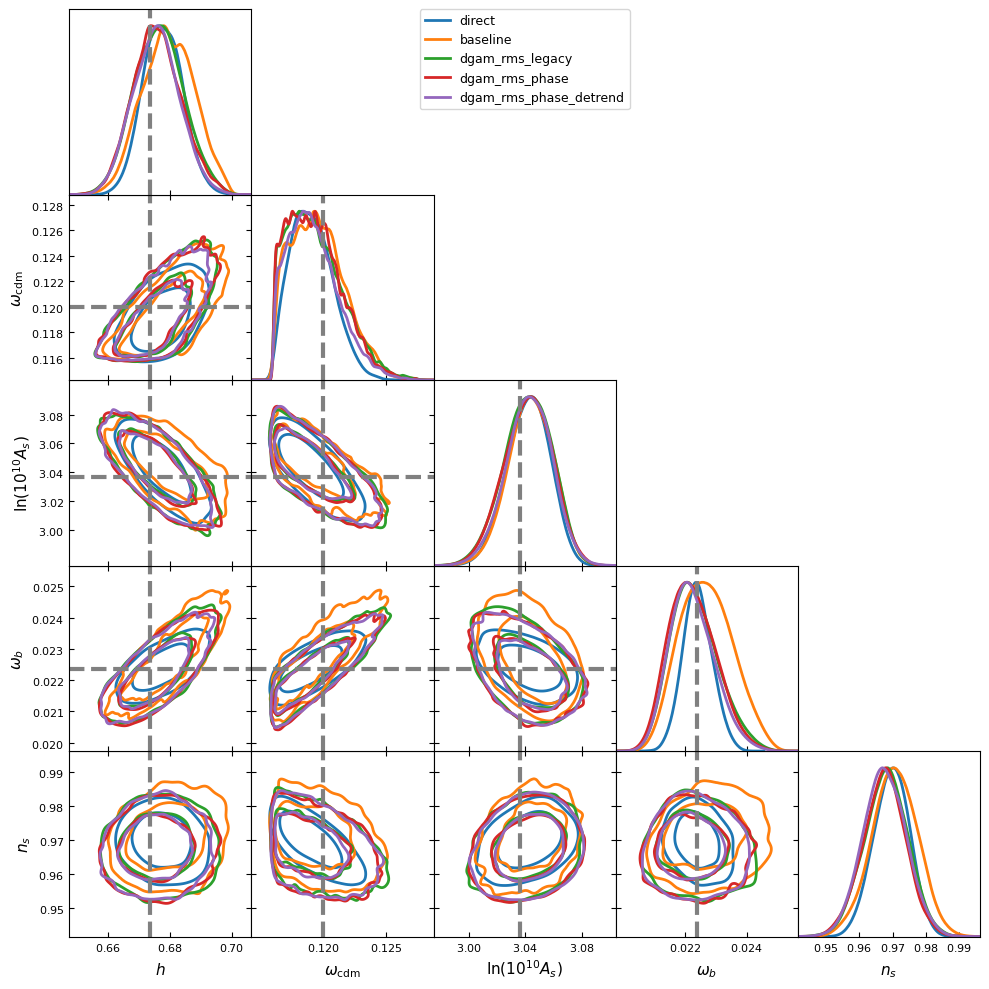

44260

In [36]:

chain_direct = MCSamples.read('_tests/chain_fs_direct/samples_1.h5').remove_burnin(0.5)[::2]
keys = [kk for kk in (['baseline'] + ['dgam_%s' % e for e in ESTS]) if kk in samples]
plotting.plot_triangle([chain_direct] + [samples[key][::2] for key in keys], params=COSMO_PARAMS,
                       labels=['direct'] + keys, filled=False,
                       markers={'h': truth['omega_cdm'] and truth['h'], 'omega_cdm': truth['omega_cdm'],
                                'logA': np.log(1e10 * cosmo_truth['A_s']), 'omega_b': truth['omega_b'],},
                      line_args = [{'lw':3, 'color':f'C{i}'}  for i in range(10)], 
                                contour_lws = 2,
                                marker_args={"lw": 3},
                               colors = [f"C{i}" for i in range(10)],)
plt.show()
plt.close('all')
gc.collect()

## 7. Why this estimator: the distillation, in one table

The three RMS variants that ship, evaluated at a few shifted cosmologies through the real
`ShapeFitTheory`, against the maximum-likelihood reference (the gamma a template fit returns,
computed offline in `study/mlfit.py`). `rms_legacy` is the original shapefit-prime definition
(fixed window in $k$, $\ln$ of the ratio): it leaks under a pure $r_d$ change and inflates
under smooth $P/P_{\rm now}$ mismatch. The shipped default fixes both with two lines of
mathematics: anchor the window on $x=k\,r_d$, and subtract a cubic in $\ln k$ before the RMS.

In [44]:
if RUN_PLOTS:
    CASES = {'f_b +5%': dict(truth, omega_b=0.02237*1.05, omega_cdm=0.14237-0.02237*1.05),
             'h +1%': dict(truth, h=truth['h']*1.01),
             'Snm +0.2': dict(truth, m_ncdm=truth['m_ncdm']+0.2)}
    ML = {'f_b +5%': +0.0749, 'h +1%': +0.0003, 'Snm +0.2': +0.0028}
    print('%-10s %9s | %9s %9s %9s' % ('case', 'ML ref', 'legacy', 'phase', 'default'))
    for cname, sh in CASES.items():
        vals = []
        for est in ('rms_legacy', 'rms_phase', 'rms_phase_detrend'):
            th = ShapeFitTheory(z=z, fiducial=FIDUCIAL, gam_estimator=est,
                                cosmo=CosmoprimoCosmology(engine='camb', fiducial=FIDUCIAL))
            pipe = build(th); d = {p.name: p._value for p in get_params(th)}
            pipe({**d, **sh}); vals.append(float(th.dgam))
            del th, pipe; gc.collect()
        print('%-10s %+9.4f | %+9.4f %+9.4f %+9.4f' % (cname, ML[cname], *vals))
    print()
    print('default = rms_phase_detrend. Diagnostics (matched-filter / linearised-ML projections,')
    print('quadrature demodulation, single-peak amplitudes) live outside the package:')
    print('study/wiggle_diagnostics.py, report shapefit_gamma.html Appendix A.')

case          ML ref |    legacy     phase   default
f_b +5%      +0.0749 |   +0.0721   +0.0734   +0.0747
h +1%        +0.0003 |   -0.0003   +0.0022   +0.0022
Snm +0.2     +0.0028 |   +0.0070   +0.0068   +0.0053

default = rms_phase_detrend. Diagnostics (matched-filter / linearised-ML projections,
quadrature demodulation, single-peak amplitudes) live outside the package:
study/wiggle_diagnostics.py, report shapefit_gamma.html Appendix A.


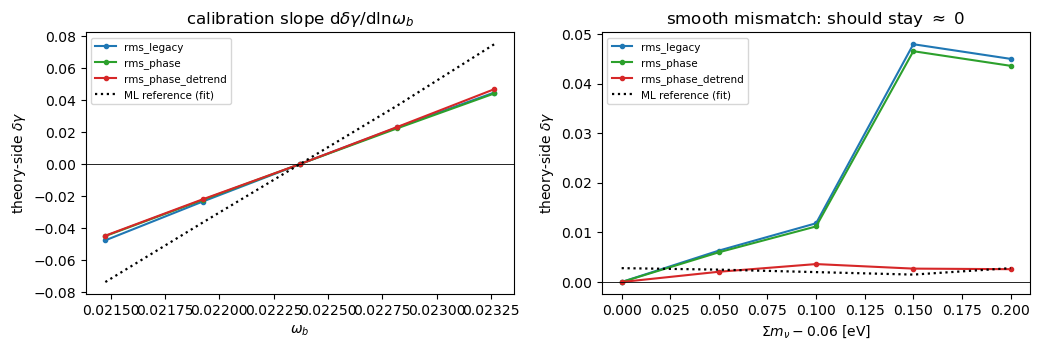

In [45]:
if RUN_PLOTS and os.environ.get('WIGGLE_NB_CURVES', '1') == '1':
    # theory-side dgam(cosmology) for the three shipped definitions, from ONE CAMB run per
    # cosmology: evaluate the standalone estimators (wiggle.py) on dense ln P / ln P_now grids
    from cosmoprimo import PowerSpectrumBAOFilter
    from desilike.theories.galaxy_clustering.wiggle import WIGGLE_ESTIMATORS, default_fine_grid
    kg = default_fine_grid()
    c0 = DESI(engine='camb')
    fo0 = c0.get_fourier(); pk0 = fo0.pk_interpolator(of='delta_cb')
    bf0 = PowerSpectrumBAOFilter(pk0, engine='peakaverage', cosmo=c0, cosmo_fid=c0)
    LP0 = np.log(pk0(kg, z=z)); LN0 = np.log(bf0.smooth_pk_interpolator()(kg, z=z))
    states = {n: WIGGLE_ESTIMATORS[n].prepare(np.log(kg), LP0, LN0, float(c0.rs_drag))
              for n in ('rms_legacy', 'rms_phase', 'rms_phase_detrend')}
    DB = (-0.04, -0.02, 0., 0.02, 0.04); DMN = (0., 0.05, 0.1, 0.15, 0.2)
    MLB = [-0.0736, -0.0365, 0.0, +0.0365, +0.0749]      # ML reference (study/mlfit.py + interpolation)
    MLS = [+0.0028, +0.0025, +0.0020, +0.0015, +0.0028]
    import jax.numpy as jnp
    fig, axx = plt.subplots(1, 2, figsize=(10.5, 3.6))
    for j, (xs, shifts, ml, xl) in enumerate((
            ([0.02237*(1+d) for d in DB], [dict(omega_b=0.02237*(1+d)) for d in DB], MLB, r'$\omega_b$'),
            (list(DMN), [dict(m_ncdm=0.06+dm) for dm in DMN], MLS, r'$\Sigma m_\nu - 0.06$ [eV]'))):
        for est, col in zip(states, ('C0', 'C2', 'C3')):
            ys = []
            for sh in shifts:
                cc = c0.clone(base='input', **sh) if sh else c0
                fo = cc.get_fourier(); pki = fo.pk_interpolator(of='delta_cb')
                bf = PowerSpectrumBAOFilter(pki, engine='peakaverage', cosmo=cc, cosmo_fid=cc)
                lp = jnp.asarray(np.log(pki(kg, z=z))); ln = jnp.asarray(np.log(bf.smooth_pk_interpolator()(kg, z=z)))
                ys.append(float(WIGGLE_ESTIMATORS[est].apply(states[est], jnp.asarray(np.log(kg)), lp, ln,
                                                             float(cc.rs_drag))))
                del cc, fo, pki, bf; gc.collect()
            axx[j].plot(xs, ys, '-o', ms=3, color=col, label=est)
        axx[j].plot(xs, ml, 'k:', lw=1.6, label='ML reference (fit)')
        axx[j].set_xlabel(xl); axx[j].set_ylabel(r'theory-side $\delta\gamma$')
        axx[j].legend(fontsize=7.5); axx[j].axhline(0, color='k', lw=0.6)
    axx[0].set_title('calibration slope d$\\delta\\gamma$/dln$\\omega_b$')
    axx[1].set_title('smooth mismatch: should stay $\\approx$ 0')
    fig.tight_layout(); plt.show()

## Reproducing / extending

* Unit tests (no engine, ~1 s): `python desilike/theories/tests/test_wiggle_estimators.py`.
* Swap-and-compare drivers on cached spectra: `study/compare_wiggle.py`,
  `study/compare_marginalise.py`, `study/compare_projection.py`.
* All definitions, derivations and forecasts: `shapefit_gamma.html` (Appendices A.1-A.7).
* Full settings: raise `min_steps` to 300/400 as in the original notebook; runtime scales
  linearly in `min_steps`, and every section resumes from `_wiggle_tests/`.